<a href="https://colab.research.google.com/github/Komal5578/DWM/blob/main/K_means_EXP7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, confusion_matrix

file_path = '/content/EEG Eye State.csv'
df = pd.read_csv(file_path)

X = df.drop("eyeDetection", axis=1)
y = df["eyeDetection"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

import numpy as np
mapped_clusters = np.where(clusters == 0,
                            1 if np.mean(y[clusters==0]) > 0.5 else 0,
                            1 if np.mean(y[clusters==1]) > 0.5 else 0)

In [ ]:
print("Confusion Matrix:")
print(confusion_matrix(y, mapped_clusters))
print("\nClassification Report:")
print(classification_report(y, mapped_clusters))

Confusion Matrix:
[[8257    0]
 [6722    1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.55      1.00      0.71      8257
           1       1.00      0.00      0.00      6723

    accuracy                           0.55     14980
   macro avg       0.78      0.50      0.36     14980
weighted avg       0.75      0.55      0.39     14980



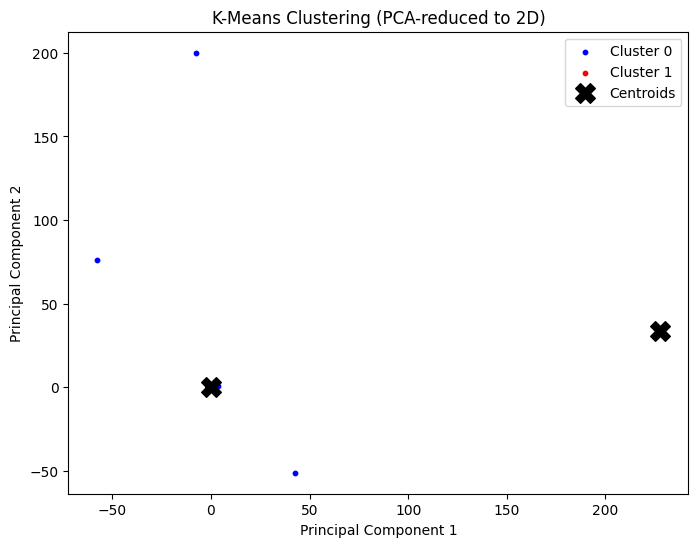

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce to 2 dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the clusters
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[clusters == 0, 0], X_pca[clusters == 0, 1],
            s=10, c='blue', label='Cluster 0')
plt.scatter(X_pca[clusters == 1, 0], X_pca[clusters == 1, 1],
            s=10, c='red', label='Cluster 1')

# Plot the centroids (transformed into PCA space)
centroids_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
            s=200, c='black', marker='X', label='Centroids')

plt.title('K-Means Clustering (PCA-reduced to 2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

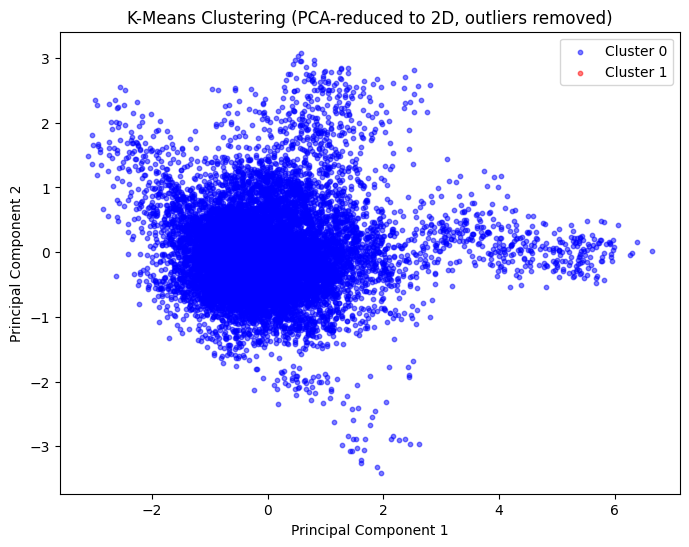

In [ ]:
import numpy as np

# Remove extreme outliers (beyond 3 std deviations) before PCA
mask = (np.abs(X_scaled) < 3).all(axis=1)
X_scaled_clean = X_scaled[mask]
clusters_clean = clusters[mask]

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled_clean)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[clusters_clean == 0, 0], X_pca[clusters_clean == 0, 1],
            s=10, c='blue', label='Cluster 0', alpha=0.5)
plt.scatter(X_pca[clusters_clean == 1, 0], X_pca[clusters_clean == 1, 1],
            s=10, c='red', label='Cluster 1', alpha=0.5)

plt.title('K-Means Clustering (PCA-reduced to 2D, outliers removed)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

In [ ]:
print("Cluster 0 count:", (clusters_clean == 0).sum())
print("Cluster 1 count:", (clusters_clean == 1).sum())

Cluster 0 count: 14892
Cluster 1 count: 0


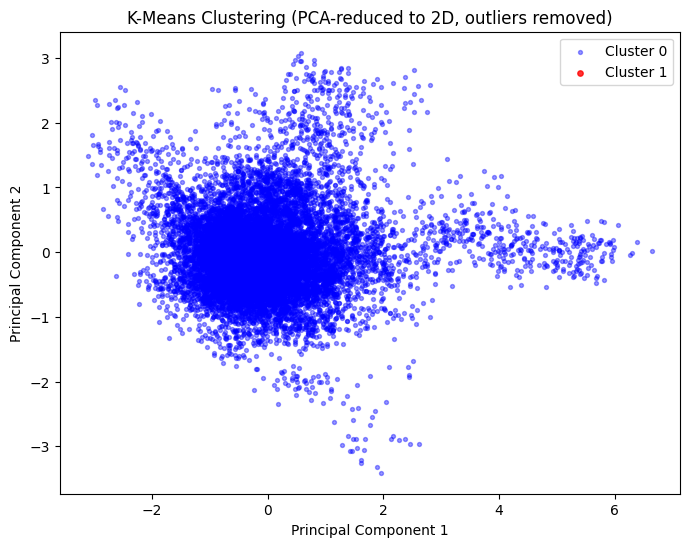

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[clusters_clean == 0, 0], X_pca[clusters_clean == 0, 1],
            s=8, c='blue', label='Cluster 0', alpha=0.4)
plt.scatter(X_pca[clusters_clean == 1, 0], X_pca[clusters_clean == 1, 1],
            s=15, c='red', label='Cluster 1', alpha=0.8, zorder=5)  # drawn on top, bigger

plt.title('K-Means Clustering (PCA-reduced to 2D, outliers removed)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

In [ ]:
print("Original Cluster 0 count:", (clusters == 0).sum())
print("Original Cluster 1 count:", (clusters == 1).sum())

Original Cluster 0 count: 14979
Original Cluster 1 count: 1


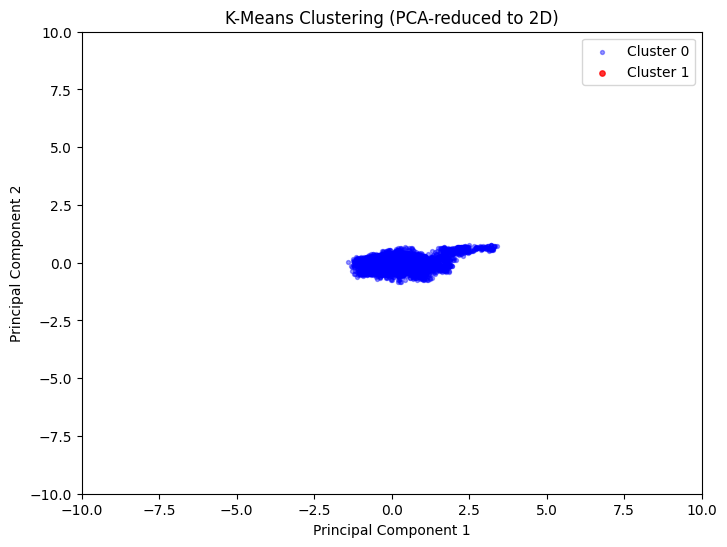

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[clusters == 0, 0], X_pca[clusters == 0, 1],
            s=8, c='blue', label='Cluster 0', alpha=0.4)
plt.scatter(X_pca[clusters == 1, 0], X_pca[clusters == 1, 1],
            s=15, c='red', label='Cluster 1', alpha=0.8, zorder=5)

plt.xlim(-10, 10)   # zoom into the dense region, ignore outliers visually
plt.ylim(-10, 10)
plt.title('K-Means Clustering (PCA-reduced to 2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

In [ ]:
print("Cluster 0 count:", (clusters == 0).sum())
print("Cluster 1 count:", (clusters == 1).sum())

Cluster 0 count: 14979
Cluster 1 count: 1


In [ ]:
import numpy as np

# Compute z-scores and remove rows with any extreme outlier value
# (threshold of 5 is generous — only removes truly extreme sensor glitches)
outlier_mask = (np.abs(X_scaled) < 5).all(axis=1)

X_scaled_clean = X_scaled[outlier_mask]
y_clean = y[outlier_mask].reset_index(drop=True)

print("Rows before:", X_scaled.shape[0])
print("Rows after removing outliers:", X_scaled_clean.shape[0])

Rows before: 14980
Rows after removing outliers: 14976


In [ ]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled_clean)

print("Cluster 0 count:", (clusters == 0).sum())
print("Cluster 1 count:", (clusters == 1).sum())



Cluster 0 count: 14130
Cluster 1 count: 846


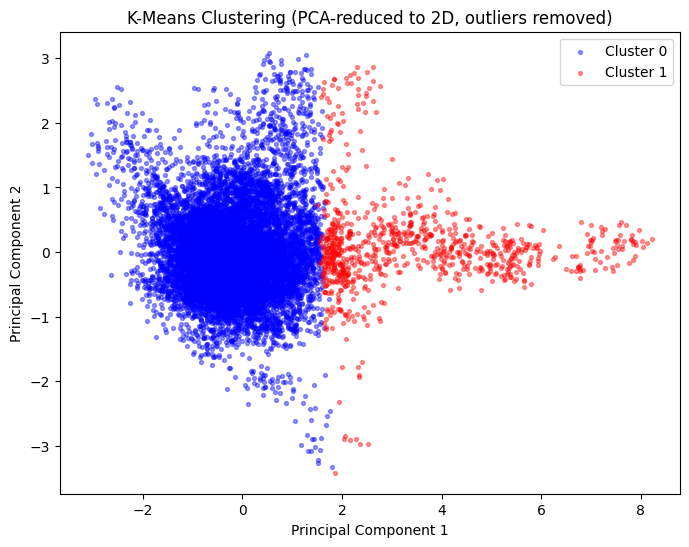

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled_clean)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[clusters == 0, 0], X_pca[clusters == 0, 1],
            s=8, c='blue', label='Cluster 0', alpha=0.4)
plt.scatter(X_pca[clusters == 1, 0], X_pca[clusters == 1, 1],
            s=8, c='red', label='Cluster 1', alpha=0.4)

plt.title('K-Means Clustering (PCA-reduced to 2D, outliers removed)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()